# Does CDS spatial subsetting use grid-cell centres or boundaries?

**It uses grid-cell centres.** For the grid shown here, a cell is selected if its centre is inside or on the requested box. A cell that overlaps the box is excluded if its centre is outside.

## Request two subsets

Use Rooki to request one day of INM-CM5-0 surface air temperature (`tas`) from the [subset-by-time demo](demo-rooki-subset-by-time.ipynb). The larger box gives us nearby cells for comparison. Rooki takes the box edges in west, south, east, north order, in degrees.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Rectangle

os.environ['ROOK_URL'] = 'http://rook.dkrz.de/wps'

from rooki import operators as ops

tas = ops.Input(
    "tas",
    ["c3s-cmip6.ScenarioMIP.INM.INM-CM5-0.ssp245.r1i1p1f1.day.tas.gr1.v20190619"],
)
bbox = (6.3, 47.2, 10.4, 50.5)
reference_bbox = (4, 45, 13, 53)


def subset(area):
    area_string = ",".join(map(str, area))
    response = ops.Subset(tas, time="2016-01-01/2016-01-01", area=area_string).orchestrate()
    if not response.ok:
        raise RuntimeError(f"Rook subset failed for {area_string}: {response.status}")
    datasets = response.datasets()
    if len(datasets) != 1:
        raise RuntimeError(f"Expected one downloadable NetCDF file for {area_string}.")
    return datasets[0]


reference = subset(reference_bbox)
selected = subset(bbox)

## Check the selected centres

Use the centres in the larger subset to check which ones Rooki returned for the requested box.

In [2]:
west, south, east, north = bbox
lon = reference.lon.values
lat = reference.lat.values

expected_lon = lon[(west <= lon) & (lon <= east)]
expected_lat = lat[(south <= lat) & (lat <= north)]

np.testing.assert_array_equal(np.sort(selected.lon.values), np.sort(expected_lon))
np.testing.assert_array_equal(np.sort(selected.lat.values), np.sort(expected_lat))

## Compare centres and cell boundaries

The dots mark grid-cell centres. Blue cells are selected. Hatched orange cells overlap the box and have their centres outside it. The cell shapes come from the NetCDF bounds.

Selected cells: 6
Overlapping excluded cells: 3


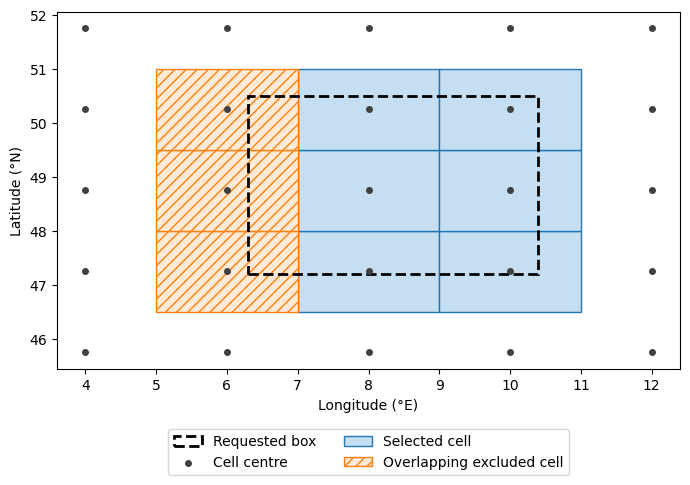

In [3]:
grid_lon, grid_lat = np.meshgrid(lon, lat)
kept = np.isin(grid_lon, selected.lon.values) & np.isin(grid_lat, selected.lat.values)

fig, ax = plt.subplots(figsize=(7, 5))
ax.add_patch(Rectangle(
    (west, south), east - west, north - south,
    fill=False, edgecolor="black", linestyle="--", linewidth=2,
    label="Requested box", zorder=3,
))
ax.scatter(grid_lon, grid_lat, color="0.25", s=16, label="Cell centre", zorder=4)
print(f"Selected cells: {np.count_nonzero(kept)}")

lon_bounds = reference.get(reference.lon.attrs.get("bounds", "lon_bnds"))
lat_bounds = reference.get(reference.lat.attrs.get("bounds", "lat_bnds"))
if lon_bounds is None or lat_bounds is None:
    ax.scatter(grid_lon[kept], grid_lat[kept], color="tab:blue", s=25,
               label="Selected centre", zorder=5)
    print("Overlapping excluded cells: unavailable because the NetCDF lacks cell bounds.")
else:
    cell_west = lon_bounds.min(dim="bnds").values
    cell_east = lon_bounds.max(dim="bnds").values
    cell_south = lat_bounds.min(dim="bnds").values
    cell_north = lat_bounds.max(dim="bnds").values
    overlaps_lon = (cell_west < east) & (cell_east > west)
    overlaps_lat = (cell_south < north) & (cell_north > south)
    excluded = overlaps_lat[:, None] & overlaps_lon & ~kept

    for mask, label, face, edge, hatch in [
        (kept, "Selected cell", "#c6def1", "tab:blue", None),
        (excluded, "Overlapping excluded cell", "#ffead7", "tab:orange", "///"),
    ]:
        for index, (row, col) in enumerate(np.argwhere(mask)):
            ax.add_patch(Rectangle(
                (cell_west[col], cell_south[row]),
                cell_east[col] - cell_west[col], cell_north[row] - cell_south[row],
                facecolor=face, edgecolor=edge, hatch=hatch,
                label=label if index == 0 else None,
            ))
    print(f"Overlapping excluded cells: {np.count_nonzero(excluded)}")

ax.set(xlabel="Longitude (°E)", ylabel="Latitude (°N)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2)
fig.tight_layout()
plt.show()

## What this means for CDS users

When you request an area, check the grid-cell centres near its edges. If you need every cell that overlaps your area, request a larger box and use the cell bounds to check which cells overlap.